In [1]:
%%capture
# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

In [2]:
# Constants
um = 1e-6
nm = 1e-9
c = 299792458

# Simulation input
- **wavelength_center** - This is the wavelength for which simulation will be done.
- **core_thickness** - Thickness of the burried oxide strip waveguide core.
- **n_modes** - Number of modes that should be inlcuded in data/ploted.
- **core material** - Material of strip waveguide core as defined in materials library of specified solver backend.
- **clad material** - Material of strip waveguide clad as defined in materials library of specified solver backend.

In [3]:
import numpy as np

wavelength_center = 1.55*um
core_thickness = 360*nm
width_sweep = np.arange(50*nm, 2000*nm, 10*nm)
n_modes = 4
core_material = {
    "lumerical": "Si3N4 (Silicon Nitride) - Luke"
}
clad_material = {
    "lumerical": "SiO2 (Glass) - Palik"
}

In [4]:
frequency_center = c / wavelength_center

# Lumerical

In [5]:
import lumapi

mode = lumapi.MODE(hide=False)

# Clad (100um x 1um x 100um)
mode.addrect(
    name="clad",
    x=0, x_span=100*um,
    y=0, y_span=1*um,
    z=0, z_span=100*um,
    material=clad_material["lumerical"]
)

# Core (Initial: core_thickness x 1um x max(width_sweep))
mode.addrect(
    name="core",
    x=0, x_span=max(width_sweep),
    y=0, y_span=1*um,
    z_min=0,z_max=core_thickness,
    material=core_material["lumerical"]
)

# FDE
mode.addfde(
    solver_type="2D Y Normal",
    x=0, x_span=10*um,
    y=0,
    z=core_thickness/2, z_span=10*um,
    number_of_trial_modes=n_modes,
    wavelength=wavelength_center,
)

# Mesh override
mode.addmesh(
    set_maximum_mesh_step=True,
    override_x_mesh=True, dx=10*nm,
    override_y_mesh=True, dy=10*nm,
    override_z_mesh=True, dz=10*nm,
    based_on_a_structure=True,
    structure="core",
)

## Width Sweep

This cell is incrementaly increasing width of the waveguide core and calculating modes for each waveguide variant.
Mode tracking is implementd using lumerical `mode.overlap()` method. 

In [6]:
modes_data = {}

def get_overlap_map(mode):
    modes_count = int(mode.nummodes())

    triplets = []
    for r in range(1, modes_count+1):
        mode_dcard = f"ref_mode{r}"
        for m in range(1, modes_count+1):
            mode_source = f"FDE::data::mode{m}"
            try:
                overlap_score = mode.overlap(mode_source, mode_dcard)[0]
            except Exception:
                overlap_score = 0

            triplets.append((overlap_score, r, m))

    triplets.sort(key=lambda x: x[0], reverse=True)

    assigned_refs = set()
    asigned_modes = set()
    mapping = {}

    for ov, r, m in triplets:
        if r not in assigned_refs and m not in asigned_modes:
            assigned_refs.add(r)
            asigned_modes.add(m)
            mapping[r] = f"FDE::data::mode{m}"

    return mapping

for i, w in enumerate(width_sweep):
    # Update core width and find modes
    mode.switchtolayout()
    mode.select("core")
    mode.set("x span", w)
    mode.findmodes()

    # Init D-CARDs with modes
    if i == 0:
        for m in range(1, n_modes + 1):
            mode.copydcard(f"FDE::data::mode{m}", f"ref_mode{m}")

    # Data extraction + mode tracking
    mapping = get_overlap_map(mode)
    for m in range(1, n_modes + 1):
        # Modes tracking on
        best_mode = mapping.get(m)
        # Modes tracking off
        #best_mode = f"FDE::data::mode{m}"
        neff = np.real(mode.getdata(best_mode, "neff").item())
        te_fraction = mode.getdata(best_mode, "TE polarization fraction")
        
        modes_data.setdefault(m, {"neff": [], "TE polarization fraction": []})
        modes_data[m]["neff"].append(neff)
        modes_data[m]["TE polarization fraction"].append(te_fraction)

    # Update D-CARDs
    try:
        mode.cleardcard()
        for m in range(1, n_modes + 1):
            best_mode = mapping.get(m)
            if best_mode is not None:
                mode.copydcard(best_mode, f"ref_mode{m}")
    except Exception as e:
        pass

In [7]:
# Get refractive index of cladding used in simulation
clad_nk_complex = mode.getmodeindex(clad_material["lumerical"], frequency_center).item()
clad_n = np.real(clad_nk_complex)

print(f"Clad refractive index at wavelength: {wavelength_center * 1e9:.1f} nm is {clad_n:.4f}")

Clad refractive index at wavelength: 1550.0 nm is 1.4440


In [8]:
processed_data = {}

for m, mode_data in modes_data.items():
    neff_arr = np.array(mode_data["neff"])
    if np.all(np.isnan(neff_arr)): continue

    te_fraction_arr = np.array(mode_data["TE polarization fraction"])
    # To label TE/TM use only guided parts of mode
    guided_te_fraction_arr = te_fraction_arr[neff_arr >= clad_n]
    guided_te_fraction_avg = np.nanmean(guided_te_fraction_arr)

    polarization_label = "quasi-TE" if guided_te_fraction_avg >= 0.5 else "quasi-TM"

    processed_data[m] = {
        "neff": neff_arr,
        "TE polarization fraction": te_fraction_arr,
        "polarization": f"{polarization_label}"
    }

modes_data = processed_data

In [9]:
# Find width where waveguide becomes multi-modal
multimode_width = None
for i, w in enumerate(width_sweep):
    guided_modes = {"quasi-TE": 0, "quasi-TM": 0}
    for mode_data in modes_data.values():
        neff = mode_data["neff"]
        polarization = mode_data["polarization"]
        if neff[i] >= clad_n:
            guided_modes[polarization] += 1
            
            # Higher order mode detected
            if guided_modes[polarization] > 1:
                # Linear interpolaation
                n_prev, n_curr = neff[i-1], neff[i]
                w_prev, w_curr = width_sweep[i-1], width_sweep[i]
                multimode_width = w_prev - (n_prev - clad_n) * (w_curr - w_prev) / (n_curr - n_prev)
                break

    if multimode_width is not None:
        break

if multimode_width is not None:
    print(f"Waveguide becomes multi-modal at width: {multimode_width * 1e9:.1f} nm")
else:
    print("Waveguide remains single-modal across all scanned widths.")

Waveguide becomes multi-modal at width: 1124.2 nm


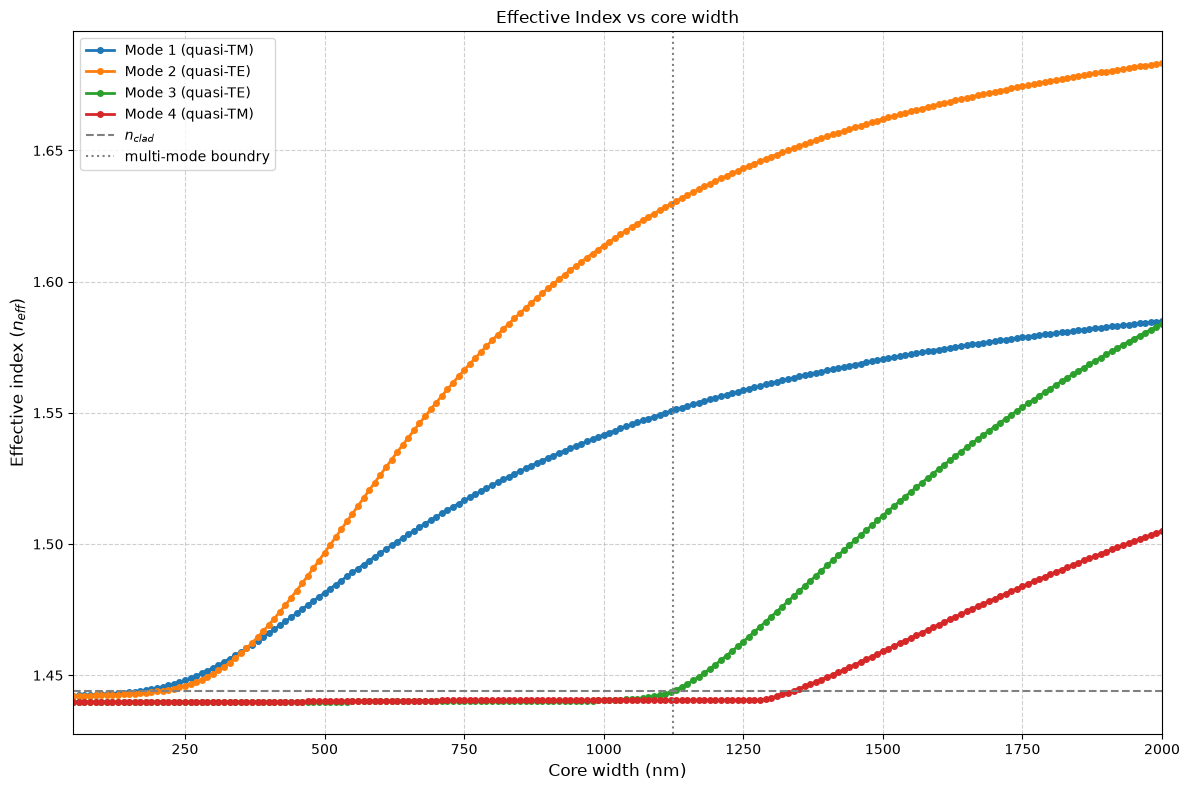

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

widths_nm = np.array(width_sweep) * 1e9

for m, mode_data in modes_data.items():
    polarization = mode_data["polarization"]
    plt.plot(
        widths_nm,
        mode_data["neff"],
        marker="o",
        markersize=4,
        linestyle="-",
        linewidth=2,
        label=f"Mode {m} ({polarization})"
    )

# Clad cutoff
plt.axhline(y=clad_n, color='gray', linestyle='--', linewidth=1.5, label=f"$n_{{clad}}$")
plt.axvline(x=multimode_width * 1e9, color='gray', linestyle=':', linewidth=1.5, label=f"multi-mode boundry")

plt.title("Effective Index vs core width", fontsize=12)
plt.xlabel("Core width (nm)", fontsize=12)
plt.ylabel("Effective index ($n_{eff}$)", fontsize=12)
plt.legend(fontsize=10, loc="best")

plt.xlim(min(widths_nm),max(widths_nm))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()